In [ ]:
!pip install ultralytics --quiet
!pip install roboflow --quiet


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 27.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 123.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 93.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 57.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 16.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 106.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.3/85.3 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install ultralytics py7zr tqdm
!pip install --upgrade --no-cache-dir gdown


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.9/67.9 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 40.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.2/96.2 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.7/50.7 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 141.3/141.3 kB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.9/412.9 kB 20.1 MB/s eta 0:00:00


dung roboflow


https://app.roboflow.com/hoangtien/my-first-project-ww9t5/annotate

In [ ]:
from ultralytics import YOLO
import os
import shutil
from google.colab import drive
from tqdm import tqdm
import glob
from sklearn.model_selection import train_test_split
from PIL import Image

# Mount Google Drive
drive.flush_and_unmount()
drive.mount('/content/drive')

# Path configuration
DATA_PATH = "/content/drive/MyDrive/cv/archive (1)"
WORK_DIR = "/content/workdir"

# Create working directory
os.makedirs(WORK_DIR, exist_ok=True)

def prepare_dataset():
    """Prepare YOLO directory structure and data.yaml with all classes"""
    classes = ['Bull', 'Cattle', 'Chicken', 'Deer', 'Duck', 'Goat',
               'Mule', 'Pig', 'Rabbit', 'Sheep', 'Turkey', 'Worm']

    # Create YOLO directory structure
    for dir_type in ['images', 'labels']:
        for split in ['train', 'val']:
            os.makedirs(os.path.join(WORK_DIR, dir_type, split), exist_ok=True)

    # Create data.yaml
    yaml_content = f"""train: {WORK_DIR}/images/train
val: {WORK_DIR}/images/val

nc: {len(classes)}
names: {classes}
"""
    with open(os.path.join(WORK_DIR, 'data.yaml'), 'w') as f:
        f.write(yaml_content)

    return classes

def generate_labels_for_images(classes):
    """Generate placeholder labels for images missing annotations"""
    for class_name in classes:
        class_path = os.path.join(DATA_PATH, class_name)
        for img_file in os.listdir(class_path):
            if img_file.lower().endswith(('.jpg', '.jpeg', '.png')):
                # Create label path
                txt_file = os.path.splitext(img_file)[0] + '.txt'
                txt_path = os.path.join(class_path, txt_file)

                # Only create if doesn't exist
                if not os.path.exists(txt_path):
                    # Get class index
                    class_idx = classes.index(class_name)

                    # Create placeholder annotation (center of image, 80% size)
                    with open(txt_path, 'w') as f:
                        f.write(f"{class_idx} 0.5 0.5 0.8 0.8")

def process_data(classes, train_ratio=0.8):
    """Process images and labels into YOLO format with proper class handling"""
    # Generate missing labels first
    generate_labels_for_images(classes)

    # Collect all image paths
    all_images = []
    for class_name in classes:
        class_path = os.path.join(DATA_PATH, class_name)
        images = glob.glob(os.path.join(class_path, '*.jpg')) + \
                 glob.glob(os.path.join(class_path, '*.jpeg')) + \
                 glob.glob(os.path.join(class_path, '*.png'))
        all_images.extend(images)

    # Split into train/val sets
    train_files, val_files = train_test_split(all_images, test_size=1-train_ratio, random_state=42)

    print(f"📊 Total images: Train={len(train_files)}, Val={len(val_files)}")

    # Copy files function
    def copy_files(file_list, split):
        for img_path in tqdm(file_list, desc=f"Processing {split} set"):
            # Copy image
            dest_img = os.path.join(WORK_DIR, 'images', split, os.path.basename(img_path))
            shutil.copyfile(img_path, dest_img)

            # Copy corresponding label
            label_path = os.path.splitext(img_path)[0] + '.txt'
            dest_label = os.path.join(WORK_DIR, 'labels', split, os.path.basename(label_path))
            shutil.copyfile(label_path, dest_label)

    copy_files(train_files, 'train')
    copy_files(val_files, 'val')


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Mounted at /content/drive


In [ ]:

# Main execution
try:
    print("🚀 Preparing dataset...")
    classes = prepare_dataset()
    print(f"🎯 Classes: {classes}")

    process_data(classes)
    print("✅ Dataset preparation complete!")

    # Initialize and train model
    print("\n🎯 Initializing YOLOv8...")
    model = YOLO('yolov8n.pt')

    print("\n🔥 Starting training...")
    results = model.train(
    data=os.path.join(WORK_DIR, 'data.yaml'),
    epochs=50,  # Train longer for better results
    imgsz=640,
    batch=8,
    workers=2,
    patience=10,
    #device='0',  # Remove or change to 'cpu' if no GPU is available
    #device='cpu',  # Use CPU for training
    exist_ok=True,
    verbose=True
    )

    # Evaluation
    print("\n📈 Evaluating model...")
    metrics = model.val()
    print(f"\n📊 Final metrics:")
    print(f"- mAP@0.5: {metrics.box.map50:.4f}")
    print(f"- mAP@0.5:0.95: {metrics.box.map:.4f}")
    print(f"- Precision: {metrics.box.mp:.4f}")
    print(f"- Recall: {metrics.box.mr:.4f}")

    # Save model
    print("\n💾 Saving model...")
    model.export(format='onnx')
    os.makedirs('/content/drive/MyDrive/cv/modelsv2', exist_ok=True)

    # Copy model files
    !cp runs/detect/train/weights/best.pt /content/drive/MyDrive/cv/modelsv2/
    !cp runs/detect/train/weights/last.pt /content/drive/MyDrive/cv/modelsv2/
    !cp runs/detect/train/weights/best.onnx /content/drive/MyDrive/cv/modelsv2/

    print("✅ Model saved to /content/drive/MyDrive/cv/modelsv2/")

except Exception as e:
    print(f"\n❌ Error occurred: {str(e)}")
    raise

🚀 Preparing dataset...
🎯 Classes: ['Bull', 'Cattle', 'Chicken', 'Deer', 'Duck', 'Goat', 'Mule', 'Pig', 'Rabbit', 'Sheep', 'Turkey', 'Worm']
📊 Total images: Train=904, Val=226


Processing val set: 100%|██████████| 226/226 [02:28<00:00,  1.52it/s]


✅ Dataset preparation complete!

🎯 Initializing YOLOv8...


100%|██████████| 6.25M/6.25M [00:00<00:00, 98.7MB/s]



🔥 Starting training...
Ultralytics 8.3.133 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/workdir/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=10, perspective=0.0, plots=True, po

...

EarlyStopping: Training stopped early as no improvement observed in last 10 epochs. Best results observed at epoch 35, best model saved as best.pt.
To update EarlyStopping(patience=10) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.

45 epochs completed in 0.322 hours.
Optimizer stripped from runs/detect/train/weights/last.pt, 6.2MB
Optimizer stripped from runs/detect/train/weights/best.pt, 6.2MB

Validating runs/detect/train/weights/best.pt...
Ultralytics 8.3.133 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 72 layers, 3,007,988 parameters, 0 gradients, 8.1 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 14/14 [00:03<00:00,  4.18it/s]


                   all        224        224      0.652      0.775      0.764      0.752
                  Bull         18         18      0.333      0.444      0.417      0.417
                Cattle         30         30      0.432      0.584      0.488      0.464
               Chicken         30         30      0.976      0.933       0.97      0.948
                  Deer         39         39      0.767      0.974        0.9      0.891
                  Duck         16         16      0.679      0.875      0.949      0.933
                  Goat         16         16      0.403        0.5      0.517      0.517
                  Mule          9          9      0.476      0.778      0.674      0.645
                   Pig         18         18      0.714          1      0.941      0.935
                Rabbit         23         23      0.846          1      0.992      0.953
                 Sheep         16         16      0.812      0.541      0.642      0.642
                Turke

val: Scanning /content/workdir/labels/val.cache... 224 images, 0 backgrounds, 0 corrupt: 100%|██████████| 224/224 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 28/28 [00:03<00:00,  7.71it/s]


                   all        224        224      0.648      0.775      0.768      0.754
                  Bull         18         18      0.332      0.444        0.4        0.4
                Cattle         30         30      0.433      0.587      0.482      0.453
               Chicken         30         30      0.975      0.933       0.97      0.938
                  Deer         39         39      0.777      0.974      0.901      0.892
                  Duck         16         16      0.679      0.875      0.949      0.933
                  Goat         16         16      0.383        0.5      0.536      0.536
                  Mule          9          9      0.474      0.778      0.721      0.691
                   Pig         18         18      0.685          1      0.937       0.93
                Rabbit         23         23      0.837          1      0.992      0.953
                 Sheep         16         16      0.811      0.539      0.645      0.645
                Turke

In [ ]:
    # Save model
    print("\n💾 Saving model...")
    model.export(format='onnx')
    os.makedirs('/content/drive/MyDrive/cv/modelsv2', exist_ok=True)

    # Copy model files
    !cp runs/detect/train/weights/best.pt /content/drive/MyDrive/cv/modelsv2/
    !cp runs/detect/train/weights/last.pt /content/drive/MyDrive/cv/modelsv2/
    !cp runs/detect/train/weights/best.onnx /content/drive/MyDrive/cv/modelsv2/

    print("✅ Model saved to /content/drive/MyDrive/cv/modelsv2/")


💾 Saving model...
Ultralytics 8.3.133 🚀 Python-3.11.12 torch-2.6.0+cu124 CPU (Intel Xeon 2.00GHz)

PyTorch: starting from 'runs/detect/train/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 16, 8400) (5.9 MB)

ONNX: starting export with onnx 1.18.0 opset 19...
ONNX: slimming with onnxslim 0.1.52...
ONNX: export success ✅ 1.1s, saved as 'runs/detect/train/weights/best.onnx' (11.7 MB)

Export complete (1.4s)
Results saved to /content/runs/detect/train/weights
Predict:         yolo predict task=detect model=runs/detect/train/weights/best.onnx imgsz=640  
Validate:        yolo val task=detect model=runs/detect/train/weights/best.onnx imgsz=640 data=/content/workdir/data.yaml  
Visualize:       https://netron.app
✅ Model saved to /content/drive/MyDrive/cv/modelsv2/


Mounted at /content/drive

🔍 Đang load mô hình...
✅ Mô hình đã load với 12 classes: {0: 'Bull', 1: 'Cattle', 2: 'Chicken', 3: 'Deer', 4: 'Duck', 5: 'Goat', 6: 'Mule', 7: 'Pig', 8: 'Rabbit', 9: 'Sheep', 10: 'Turkey', 11: 'Worm'}

🔎 Đang lấy ảnh ngẫu nhiên từ dataset...

📌 Đang xử lý ảnh: 906e395e20e79a39.jpg
📂 Thư mục: Mule

image 1/1 /content/drive/MyDrive/cv/archive (1)/Mule/906e395e20e79a39.jpg: 448x640 1 Mule, 178.1ms
Speed: 7.5ms preprocess, 178.1ms inference, 11.2ms postprocess per image at shape (1, 3, 448, 640)


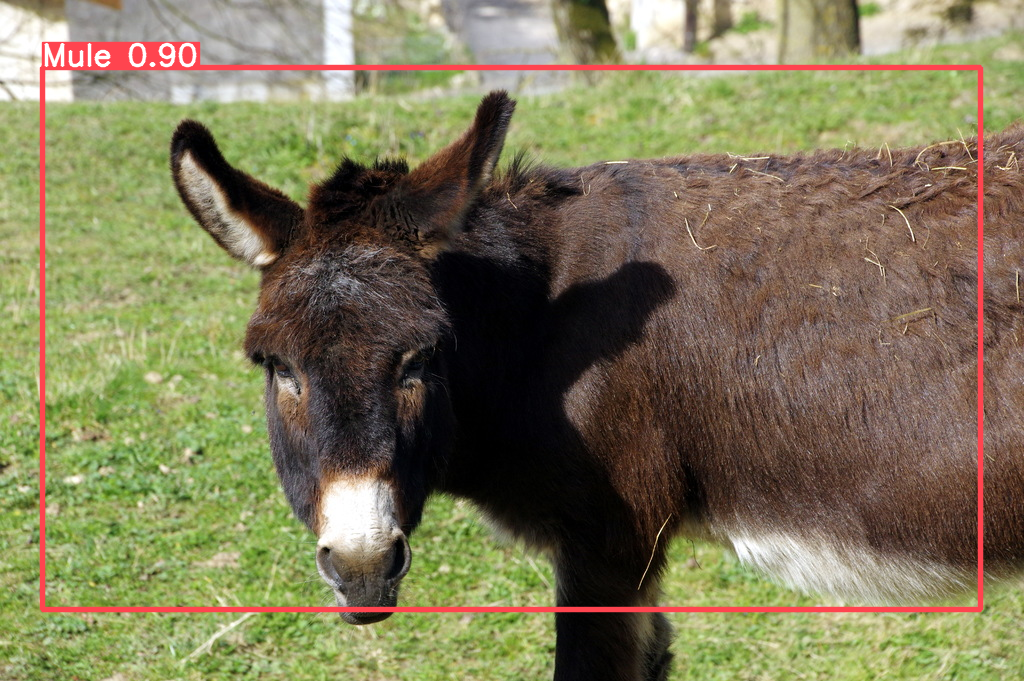


📊 Kết quả phát hiện:
- Mule: 89.92%

📌 Đang xử lý ảnh: 384c86c0147ceeb2.jpg
📂 Thư mục: Deer

image 1/1 /content/drive/MyDrive/cv/archive (1)/Deer/384c86c0147ceeb2.jpg: 448x640 1 Deer, 22.3ms
Speed: 9.5ms preprocess, 22.3ms inference, 1.9ms postprocess per image at shape (1, 3, 448, 640)


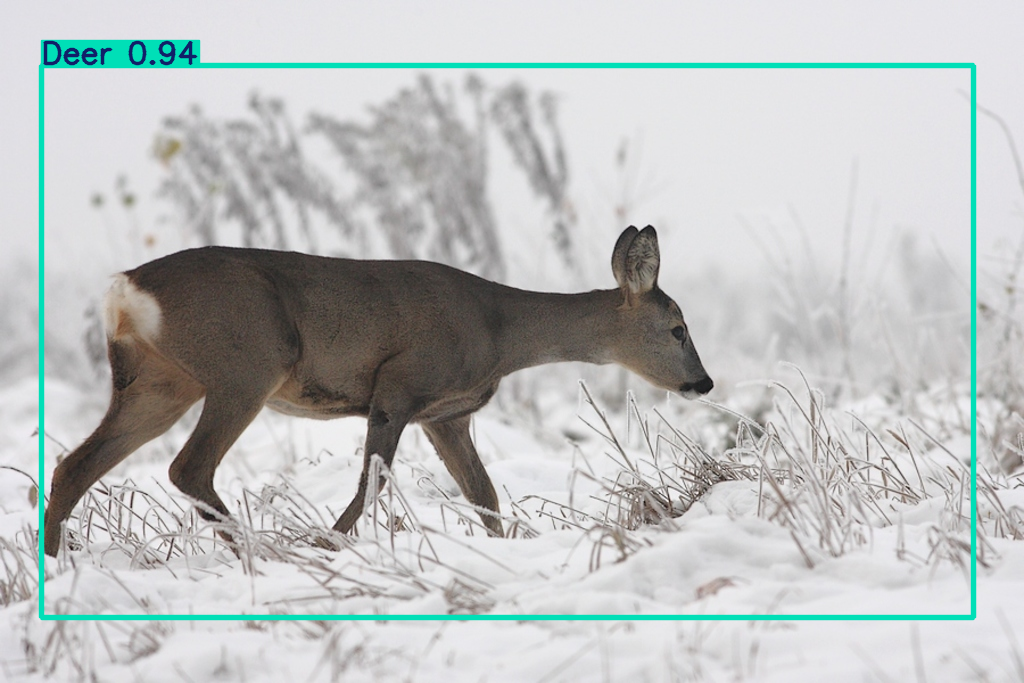


📊 Kết quả phát hiện:
- Deer: 94.28%

📌 Đang xử lý ảnh: c5e088383cbe7c41.jpg
📂 Thư mục: Cattle

image 1/1 /content/drive/MyDrive/cv/archive (1)/Cattle/c5e088383cbe7c41.jpg: 448x640 1 Cattle, 21.4ms
Speed: 4.8ms preprocess, 21.4ms inference, 2.2ms postprocess per image at shape (1, 3, 448, 640)


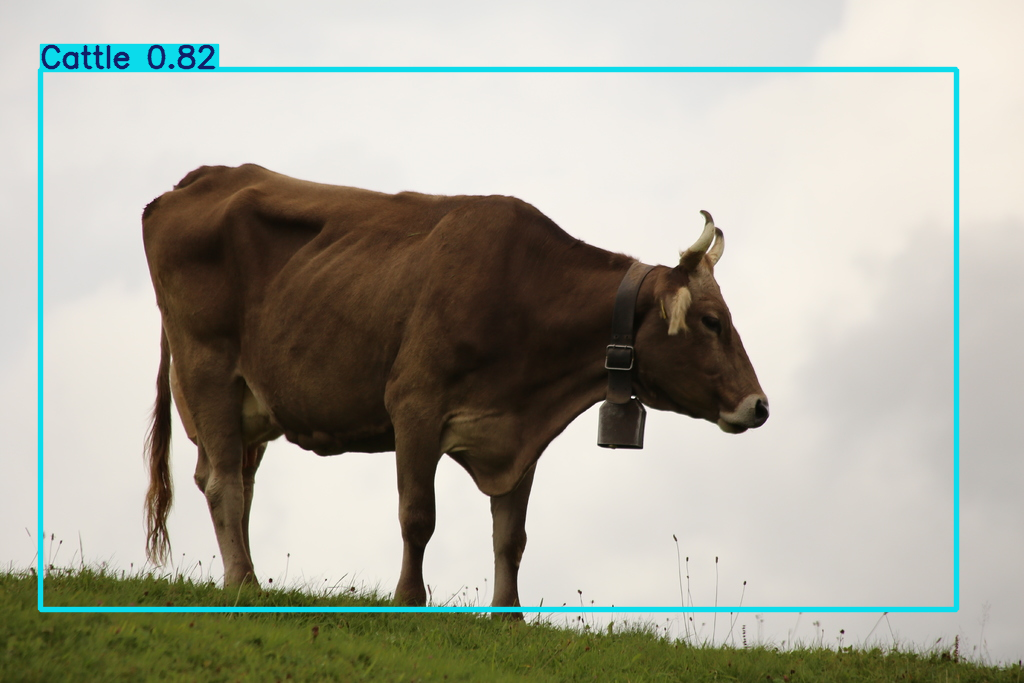


📊 Kết quả phát hiện:
- Cattle: 82.35%


In [ ]:
# --------------------------
# TEST MÔ HÌNH TRÊN ẢNH TỪ THƯ MỤC DATA_CATTLE
# --------------------------

from ultralytics import YOLO
import cv2
from google.colab.patches import cv2_imshow
import os
import random
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive', force_remount=True)

# Cấu hình đường dẫn
MODEL_PATH = "/content/drive/MyDrive/cv/modelsv2/best.pt"
DATA_ROOT = "/content/drive/MyDrive/cv/archive (1)"

# Load mô hình
print("\n🔍 Đang load mô hình...")
model = YOLO(MODEL_PATH)
print(f"✅ Mô hình đã load với {len(model.names)} classes: {model.names}")

# Hàm lấy ngẫu nhiên ảnh từ các thư mục con
def get_random_test_images(num_images=3):
    test_images = []

    # Duyệt qua tất cả thư mục lớp
    for class_name in os.listdir(DATA_ROOT):
        class_path = os.path.join(DATA_ROOT, class_name)
        if os.path.isdir(class_path):
            # Lấy tất cả ảnh trong thư mục lớp
            images = [os.path.join(class_path, f) for f in os.listdir(class_path)
                     if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
            test_images.extend(images)

    # Trộn ngẫu nhiên và chọn số lượng ảnh cần test
    random.shuffle(test_images)
    return test_images[:num_images]

# Hàm hiển thị kết quả
def show_prediction(image_path):
    try:
        print(f"\n📌 Đang xử lý ảnh: {os.path.basename(image_path)}")
        print(f"📂 Thư mục: {os.path.basename(os.path.dirname(image_path))}")

        # Dự đoán với ngưỡng confidence 50%
        results = model.predict(image_path, conf=0.5)

        # Hiển thị ảnh với bounding boxes
        for r in results:
            im_array = r.plot()
            cv2_imshow(im_array)

        # In kết quả chi tiết
        print("\n📊 Kết quả phát hiện:")
        for i, r in enumerate(results):
            for box in r.boxes:
                class_name = model.names[int(box.cls)]
                conf = box.conf.item()
                print(f"- {class_name}: {conf:.2%}")

    except Exception as e:
        print(f"❌ Lỗi khi xử lý ảnh: {e}")

# Lấy và xử lý ảnh test
try:
    print("\n🔎 Đang lấy ảnh ngẫu nhiên từ dataset...")
    test_images = get_random_test_images(3)  # Lấy 3 ảnh ngẫu nhiên

    if not test_images:
        print(f"⚠️ Không tìm thấy ảnh nào trong {DATA_ROOT}")
        print("💡 Hãy kiểm tra lại đường dẫn và định dạng ảnh (jpg/png)")
    else:
        for img_path in test_images:
            show_prediction(img_path)

except Exception as e:
    print(f"\n❌ Lỗi trong quá trình test: {e}")

In [ ]:
model = YOLO('/content/drive/MyDrive/cv/modelsv2/best.pt')  # hoặc best.pt cũng được

# Huấn luyện thêm 30 epoch (training mới, nhưng với weight cũ)
model.train(
    data='/content/workdir/data.yaml',
    epochs=30,
    project='/content/drive/MyDrive/cv/modelsv2',
    name='retrain',  # tên thư mục mới để lưu kết quả
    resume=False  # KHÔNG dùng resume!
)

Ultralytics 8.3.133 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/workdir/data.yaml, degrees=0.0, deterministic=True, device=-1, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/cv/modelsv2/best.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=retrain, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plo

train: Scanning /content/workdir/labels/train.cache... 854 images, 0 backgrounds, 0 corrupt: 100%|██████████| 854/854 [00:00<?, ?it/s]

albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))


val: Fast image access ✅ (ping: 0.0±0.1 ms, read: 1167.4±1248.1 MB/s, size: 396.5 KB)


val: Scanning /content/workdir/labels/val.cache... 224 images, 0 backgrounds, 0 corrupt: 100%|██████████| 224/224 [00:00<?, ?it/s]


...

                   all        224        224      0.668      0.688      0.726      0.726



30 epochs completed in 0.196 hours.
Optimizer stripped from /content/drive/MyDrive/cv/modelsv2/retrain/weights/last.pt, 6.2MB
Optimizer stripped from /content/drive/MyDrive/cv/modelsv2/retrain/weights/best.pt, 6.2MB

Validating /content/drive/MyDrive/cv/modelsv2/retrain/weights/best.pt...
Searching for 1 idle GPUs with >= 2048 MiB free memory...
Selected idle CUDA devices [0]
Ultralytics 8.3.133 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 72 layers, 3,007,988 parameters, 0 gradients, 8.1 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 7/7 [00:04<00:00,  1.75it/s]


                   all        224        224      0.731      0.689      0.741      0.731
                  Bull         18         18      0.155      0.123      0.445      0.445
                Cattle         30         30      0.412      0.375      0.422      0.411
               Chicken         30         30      0.946      0.933      0.966      0.923
                  Deer         39         39      0.796      0.949      0.902      0.894
                  Duck         16         16       0.91      0.875      0.918      0.902
                  Goat         16         16      0.453       0.62      0.494      0.494
                  Mule          9          9          1      0.409       0.65       0.65
                   Pig         18         18      0.674      0.944      0.924      0.924
                Rabbit         23         23      0.992      0.957      0.993      0.959
                 Sheep         16         16      0.767      0.414      0.503      0.503
                Turke

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7bd4dfebfbd0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,  


image 1/1 /content/istockphoto-482295174-612x612.jpg: 448x640 3 sheeps, 5 cows, 28.1ms
Speed: 2.1ms preprocess, 28.1ms inference, 1.5ms postprocess per image at shape (1, 3, 448, 640)
Results saved to runs/detect/predict22

🔍 Kết quả đếm số lượng từng loài trong ảnh:
- Sheep: 3
- Cow: 5


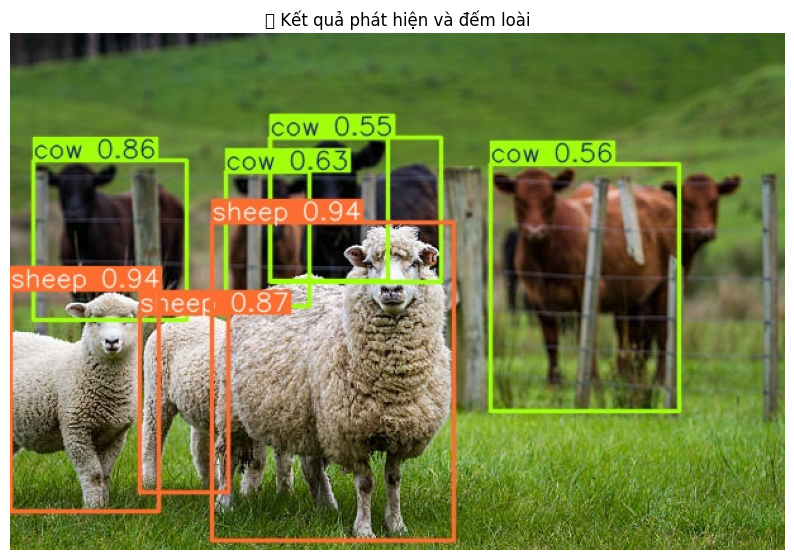

In [ ]:
from ultralytics import YOLO
from collections import Counter
import cv2
from matplotlib import pyplot as plt

# Load model
model = ('/content/drive/MyDrive/models/best.pt')

coco_to_custom = {
    21: 'Bull',
    20: 'Cattle',
    16: 'Chicken',
    22: 'Deer',
    16: 'Duck',
    20: 'Goat',
    24: 'Mule',
    17: 'Pig',
    24: 'Rabbit',
    20: 'Sheep',
    16: 'Turkey',
    8: 'Worm'
}

animal_classes_of_interest = {
    14: 'Bird',
    15: 'Cat',
    16: 'Dog',
    17: 'Horse',
    18: 'Sheep',
    19: 'Cow',
    20: 'Elephant',
    21: 'Bear',
    22: 'Zebra',
    23: 'Giraffe'
}

image_path = '/content/istockphoto-482295174-612x612.jpg'

results = model.predict(image_path, save=True)

detections = results[0].boxes.cls.tolist()

filtered_detections = [int(d) for d in detections if int(d) in animal_classes_of_interest]

# Count per class
count_per_class = Counter(filtered_detections)

# Print results
print("\n🔍 Kết quả đếm số lượng từng loài trong ảnh:")
for class_idx, count in count_per_class.items():
    class_name = animal_classes_of_interest.get(class_idx, f'Unknown Class (index {class_idx})')
    print(f"- {class_name}: {count}")

# Display the image with bounding boxes
predicted_img_path = f"{results[0].save_dir}/{image_path.split('/')[-1]}"

# Read and display image
img = cv2.imread(predicted_img_path)
if img is not None:
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(10, 8))
    plt.imshow(img)
    plt.axis('off')
    plt.title("📸 Kết quả phát hiện và đếm loài")
    plt.show()
else:
    print(f"Could not load image from {predicted_img_path}")


image 1/1 /content/drive/MyDrive/data_cattle/Cattle/96e1df5761f3d591.jpg: 480x640 4 cows, 28.8ms
Speed: 2.5ms preprocess, 28.8ms inference, 1.5ms postprocess per image at shape (1, 3, 480, 640)
Results saved to runs/detect/predict24

🔍 Kết quả đếm số lượng từng loài trong ảnh:
- Cow: 4


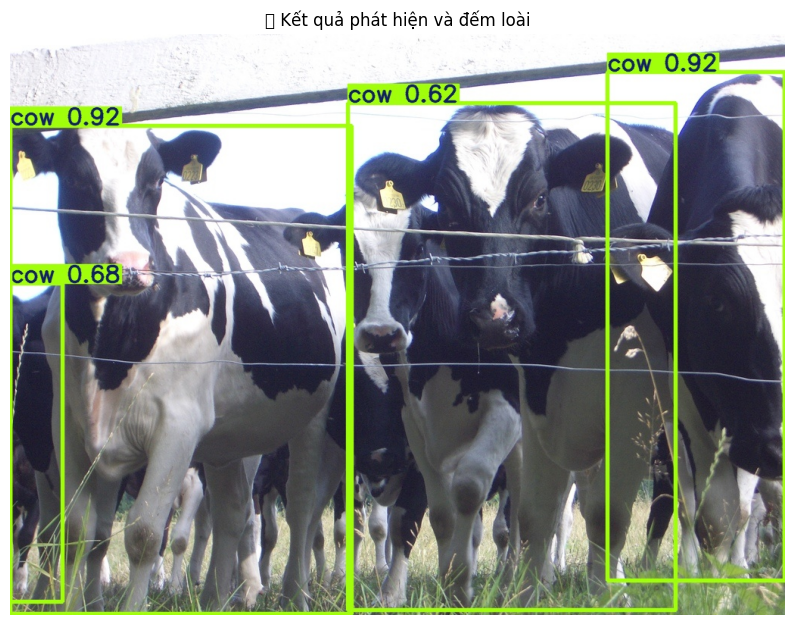

In [ ]:
from ultralytics import YOLO
from collections import Counter
import cv2
from matplotlib import pyplot as plt

# Load model
model = ('/content/drive/MyDrive/models/best.pt')

coco_to_custom = {
    21: 'Bull',
    20: 'Cattle',
    16: 'Chicken',
    22: 'Deer',
    16: 'Duck',
    20: 'Goat',
    24: 'Mule',
    17: 'Pig',
    24: 'Rabbit',
    20: 'Sheep',
    16: 'Turkey',
    8: 'Worm'
}

animal_classes_of_interest = {
    14: 'Bird',
    15: 'Cat',
    16: 'Dog',
    17: 'Horse',
    18: 'Sheep',
    19: 'Cow',
    20: 'Elephant',
    21: 'Bear',
    22: 'Zebra',
    23: 'Giraffe'
}

image_path = '/content/drive/MyDrive/data_cattle/Cattle/96e1df5761f3d591.jpg'

results = model.predict(image_path, save=True)

detections = results[0].boxes.cls.tolist()

filtered_detections = [int(d) for d in detections if int(d) in animal_classes_of_interest]

# Count per class
count_per_class = Counter(filtered_detections)

# Print results
print("\n🔍 Kết quả đếm số lượng từng loài trong ảnh:")
for class_idx, count in count_per_class.items():
    class_name = animal_classes_of_interest.get(class_idx, f'Unknown Class (index {class_idx})')
    print(f"- {class_name}: {count}")

# Display the image with bounding boxes
predicted_img_path = f"{results[0].save_dir}/{image_path.split('/')[-1]}"

# Read and display image
img = cv2.imread(predicted_img_path)
if img is not None:
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(10, 8))
    plt.imshow(img)
    plt.axis('off')
    plt.title("📸 Kết quả phát hiện và đếm loài")
    plt.show()
else:
    print(f"Could not load image from {predicted_img_path}")

In [ ]:
!pip install ultralytics --quiet


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 31.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 124.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 83.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 57.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 106.8 MB/s eta 0:00:00


In [ ]:
import os
import yaml
from glob import glob

# Đường dẫn đến thư mục dataset gốc của bạn
DATA_ROOT = "/content/drive/MyDrive/archive (1)"

# Tạo danh sách các lớp tự động từ thư mục con
classes = [d for d in os.listdir(DATA_ROOT) if os.path.isdir(os.path.join(DATA_ROOT, d))]
classes.sort()  # Sắp xếp theo thứ tự alphabet

# Tạo thư mục YOLO structure
WORK_DIR = "/content/workdir"
os.makedirs(os.path.join(WORK_DIR, "images", "train"), exist_ok=True)
os.makedirs(os.path.join(WORK_DIR, "images", "val"), exist_ok=True)
os.makedirs(os.path.join(WORK_DIR, "labels", "train"), exist_ok=True)
os.makedirs(os.path.join(WORK_DIR, "labels", "val"), exist_ok=True)

# Tạo file data.yaml
data_yaml = {
    'train': f"{WORK_DIR}/images/train",
    'val': f"{WORK_DIR}/images/val",
    'nc': len(classes),
    'names': classes
}

with open(os.path.join(WORK_DIR, 'data.yaml'), 'w') as f:
    yaml.dump(data_yaml, f, default_flow_style=False)

print("✅ Đã tạo file data.yaml với các lớp:")
print('\n'.join(f"{i}: {cls}" for i, cls in enumerate(classes)))

# Hàm tạo label tự động nếu chưa có
def create_yolo_label(img_path, class_id):
    txt_path = os.path.splitext(img_path)[0] + '.txt'
    if not os.path.exists(txt_path):
        with open(txt_path, 'w') as f:
            f.write(f"{class_id} 0.5 0.5 0.8 0.8")  # Tạo label ở giữa ảnh với kích thước 80%

# Copy và phân chia dữ liệu
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import shutil

all_images = []
for class_id, class_name in enumerate(classes):
    class_dir = os.path.join(DATA_ROOT, class_name)
    images = glob(os.path.join(class_dir, '*.jpg')) + glob(os.path.join(class_dir, '*.jpeg')) + glob(os.path.join(class_dir, '*.png'))

    for img_path in images:
        # Tạo label nếu chưa có
        create_yolo_label(img_path, class_id)
        all_images.append((img_path, class_id))

# Phân chia train/val (80/20)
train_files, val_files = train_test_split(all_images, test_size=0.2, random_state=42)

# Copy files vào thư mục YOLO
def copy_files(file_list, split):
    for img_path, class_id in tqdm(file_list, desc=f"Copying {split} files"):
        # Copy image
        img_name = os.path.basename(img_path)
        dest_img = os.path.join(WORK_DIR, 'images', split, img_name)
        shutil.copy(img_path, dest_img)

        # Copy label
        txt_path = os.path.splitext(img_path)[0] + '.txt'
        txt_name = os.path.basename(txt_path)
        dest_txt = os.path.join(WORK_DIR, 'labels', split, txt_name)
        shutil.copy(txt_path, dest_txt)

copy_files(train_files, 'train')
copy_files(val_files, 'val')

print("\n🎉 Đã chuẩn bị xong dataset với cấu trúc YOLO!")
print(f"📂 Train samples: {len(train_files)}")
print(f"📂 Val samples: {len(val_files)}")
print(f"📝 File cấu hình: {WORK_DIR}/data.yaml")

# Hiển thị nội dung file data.yaml
print("\n📜 Nội dung file data.yaml:")
with open(os.path.join(WORK_DIR, 'data.yaml')) as f:
    print(f.read())

✅ Đã tạo file data.yaml với các lớp:
0: Bull
1: Cattle
2: Chicken
3: Deer
4: Duck
5: Goat
6: Mule
7: Pig
8: Rabbit
9: Sheep
10: Turkey
11: Worm


Copying val files: 100%|██████████| 226/226 [02:44<00:00,  1.37it/s]


🎉 Đã chuẩn bị xong dataset với cấu trúc YOLO!
📂 Train samples: 904
📂 Val samples: 226
📝 File cấu hình: /content/workdir/data.yaml

📜 Nội dung file data.yaml:
names:
- Bull
- Cattle
- Chicken
- Deer
- Duck
- Goat
- Mule
- Pig
- Rabbit
- Sheep
- Turkey
- Worm
nc: 12
train: /content/workdir/images/train
val: /content/workdir/images/val



Ultralytics 8.3.139 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 72 layers, 3,007,988 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2012.3±625.7 MB/s, size: 335.7 KB)


val: Scanning /content/workdir/labels/val.cache... 220 images, 0 backgrounds, 0 corrupt: 100%|██████████| 220/220 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 14/14 [00:04<00:00,  3.46it/s]


                   all        220        220      0.845      0.856      0.899       0.89
                  Bull         17         17      0.525      0.412      0.521      0.521
                Cattle         28         28      0.662      0.714      0.765      0.749
               Chicken         30         30          1      0.919      0.953       0.93
                  Deer         39         39       0.95      0.984      0.958      0.956
                  Duck         16         16      0.954          1      0.995      0.995
                  Goat         16         16      0.693      0.812      0.808      0.808
                  Mule          9          9      0.875      0.778      0.921      0.898
                   Pig         18         18      0.936          1      0.992      0.992
                Rabbit         23         23      0.998          1      0.995      0.954
                 Sheep         15         15          1      0.647      0.935      0.935
                Turke

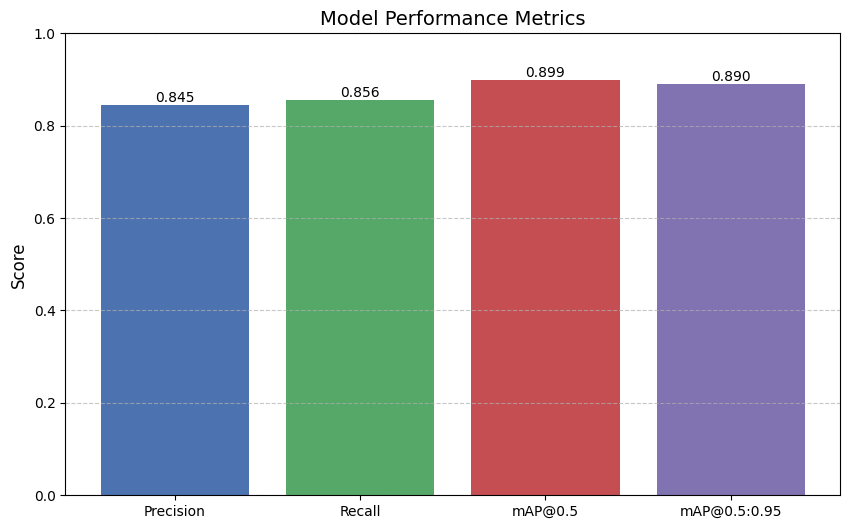


🎯 MA TRẬN NHẦM LẪN (CONFUSION MATRIX):


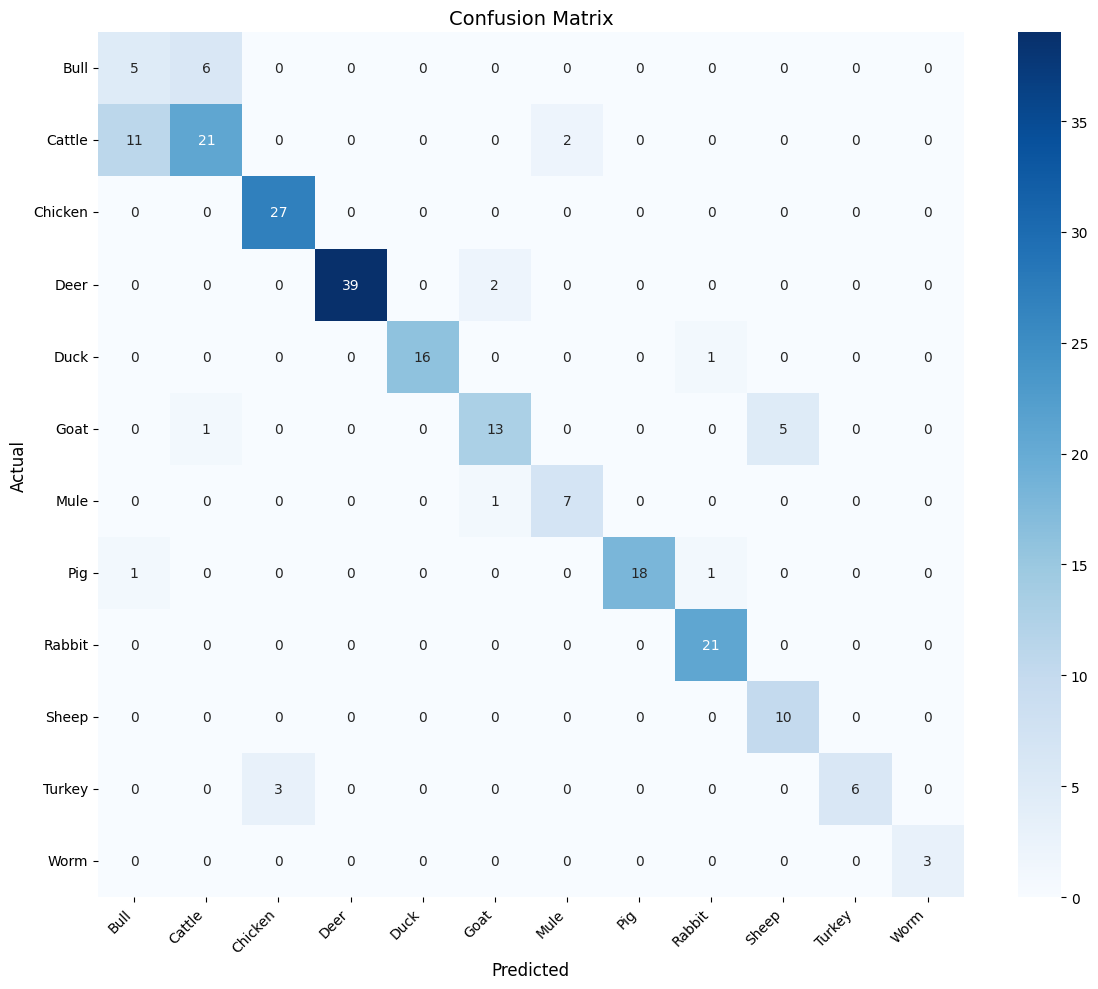


❌ CÁC LỖI PHỔ BIẾN:
    Actual Predicted  Count
1   Cattle      Bull   11.0
0     Bull    Cattle    6.0
6     Goat     Sheep    5.0
10  Turkey   Chicken    3.0
2   Cattle      Mule    2.0
3     Deer      Goat    2.0
4     Duck    Rabbit    1.0
5     Goat    Cattle    1.0
7     Mule      Goat    1.0
8      Pig      Bull    1.0


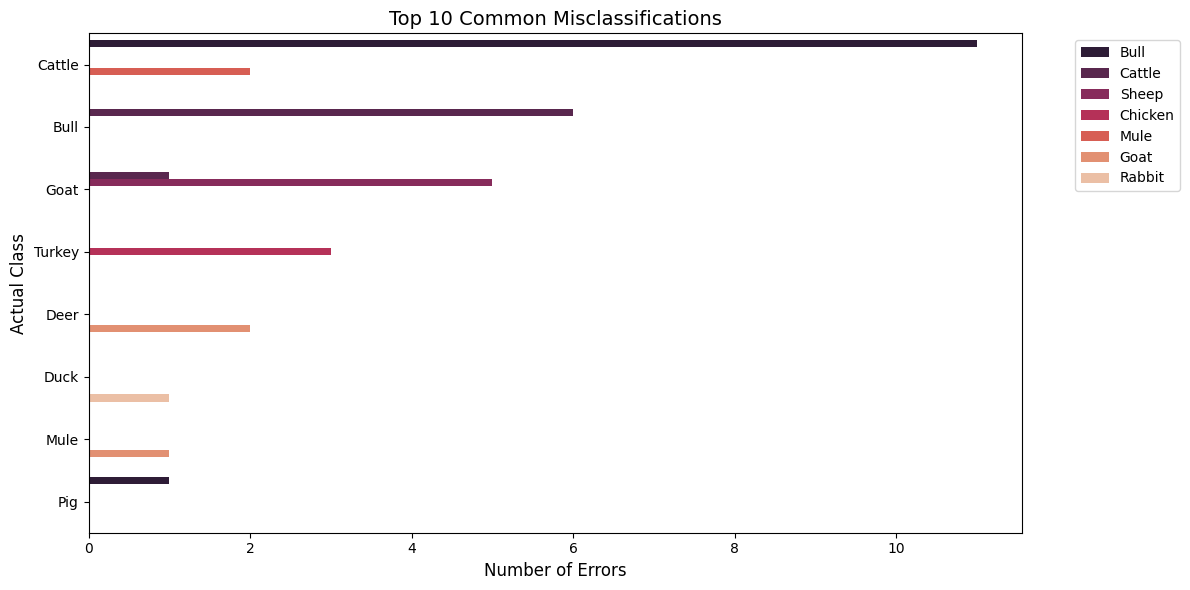

In [ ]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import pandas as pd
import cv2
from google.colab.patches import cv2_imshow

# 1. Load model và dữ liệu
model = YOLO('/content/drive/MyDrive/models/best.pt')
val_results = model.val(data='/content/workdir/data.yaml', split='val')

# 2. Phân tích metrics tổng quan
print("\n📊 TỔNG QUAN ĐÁNH GIÁ MÔ HÌNH")
print(f"- mAP@0.5: {val_results.box.map50:.4f}")
print(f"- mAP@0.5:0.95: {val_results.box.map:.4f}")
print(f"- Precision: {val_results.box.mp:.4f}")
print(f"- Recall: {val_results.box.mr:.4f}")

# 3. Visualization metrics
def plot_metrics(results):
    metrics = {
        'Precision': results.box.mp,
        'Recall': results.box.mr,
        'mAP@0.5': results.box.map50,
        'mAP@0.5:0.95': results.box.map
    }

    plt.figure(figsize=(10, 6))
    bars = plt.bar(metrics.keys(), metrics.values(), color=['#4C72B0', '#55A868', '#C44E52', '#8172B2'])
    plt.title('Model Performance Metrics', fontsize=14)
    plt.ylabel('Score', fontsize=12)
    plt.ylim(0, 1)

    # Thêm giá trị trên mỗi cột
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}',
                ha='center', va='bottom')

    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

plot_metrics(val_results)

# 4. Phân tích từng class
if hasattr(val_results, 'boxes'):
    print("\n🔍 CHI TIẾT TỪNG LỚP:")
    class_metrics = []
    # Use the actual class indices from the results object if available,
    # otherwise iterate based on the number of classes in model.names
    num_classes = len(model.names)
    # Safely iterate up to the number of classes the model is trained on
    for i in range(num_classes):
         # Ensure indices exist in the results arrays
         if i < len(val_results.box.precision) and i < len(val_results.box.recall) and \
            i < len(val_results.box.map50_per_class) and i < len(val_results.box.map_per_class):
            precision = val_results.box.precision[i]
            recall = val_results.box.recall[i]
            map50 = val_results.box.map50_per_class[i]
            map = val_results.box.map_per_class[i]
            class_name = model.names[i] # Access by index
            class_metrics.append({
                'Class': class_name,
                'Precision': precision.mean() if isinstance(precision, np.ndarray) else precision, # Handle potential list/ndarray
                'Recall': recall.mean() if isinstance(recall, np.ndarray) else recall,
                'mAP@0.5': map50,
                'mAP@0.5:0.95': map
            })


    # Hiển thị bảng metrics
    df_metrics = pd.DataFrame(class_metrics)
    print(df_metrics.sort_values(by='mAP@0.5', ascending=False))

    # Visualization
    plt.figure(figsize=(12, 8))
    df_melt = df_metrics.melt(id_vars='Class', var_name='Metric', value_name='Value')
    sns.barplot(x='Value', y='Class', hue='Metric', data=df_melt, palette='viridis')
    plt.title('Performance Metrics by Class', fontsize=14)
    plt.xlabel('Score', fontsize=12)
    plt.ylabel('Class', fontsize=12)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

# 5. Confusion Matrix
if hasattr(val_results, 'confusion_matrix'):
    print("\n🎯 MA TRẬN NHẦM LẪN (CONFUSION MATRIX):")
    conf_matrix = val_results.confusion_matrix.matrix
    num_classes = len(model.names)

    # Only plot the confusion matrix for the actual number of classes
    plt.figure(figsize=(12, 10))
    sns.heatmap(conf_matrix[:num_classes, :num_classes], annot=True, fmt='g', # Slice the matrix
                xticklabels=[model.names[k] for k in range(num_classes)], # Generate labels from model.names
                yticklabels=[model.names[k] for k in range(num_classes)],
                cmap='Blues')
    plt.title('Confusion Matrix', fontsize=14)
    plt.xlabel('Predicted', fontsize=12)
    plt.ylabel('Actual', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

# 6. Phân tích lỗi phổ biến
if hasattr(val_results, 'confusion_matrix'):
    conf_matrix = val_results.confusion_matrix.matrix
    num_classes = len(model.names) # Get the number of classes from the model
    errors = []

    # Iterate only up to the number of classes defined in model.names
    for i in range(num_classes):
        for j in range(num_classes):
            # Check if the indices exist in model.names before accessing
            if i in model.names and j in model.names and i != j and conf_matrix[i,j] > 0:
                errors.append({
                    'Actual': model.names[i],
                    'Predicted': model.names[j],
                    'Count': conf_matrix[i,j]
                })

    df_errors = pd.DataFrame(errors).sort_values('Count', ascending=False)
    if not df_errors.empty:
        print("\n❌ CÁC LỖI PHỔ BIẾN:")
        print(df_errors.head(10))

        # Visualization
        plt.figure(figsize=(12, 6))
        sns.barplot(x='Count', y='Actual', hue='Predicted',
                    data=df_errors.head(10), palette='rocket')
        plt.title('Top 10 Common Misclassifications', fontsize=14)
        plt.xlabel('Number of Errors', fontsize=12)
        plt.ylabel('Actual Class', fontsize=12)
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.tight_layout()
        plt.show()

# 7. Phân tích detection trên ảnh mẫu
def analyze_sample_detections(model, image_path, conf_thresh=0.5):
    results = model.predict(image_path, conf=conf_thresh)

    print(f"\n🔎 PHÂN TÍCH PHÁT HIỆN TRÊN ẢNH: {image_path}")

    for i, r in enumerate(results):
        # Hiển thị ảnh với bounding boxes
        im_array = r.plot()
        cv2_imshow(im_array)

        # Phân tích chi tiết
        print("\n📊 THÔNG TIN PHÁT HIỆN:")
        for box in r.boxes:
            class_id = int(box.cls)
            conf = box.conf.item()
            bbox = box.xyxy[0].tolist()
            # Check if class_id exists in model.names before accessing
            class_name = model.names.get(class_id, f'Unknown Class (index {class_id})')
            print(f"- {class_name}: Độ tin cậy {conf:.2%} | Bounding box: {bbox}")

        # Thống kê
        detections = [int(b.cls) for b in r.boxes]
        if detections:
            detection_counts = {model.names.get(i, f'Unknown Class (index {i})'): detections.count(i) for i in set(detections) if i in model.names}
            print("\n📈 THỐNG KÊ:")
            for cls, count in detection_counts.items():
                print(f"- {cls}: {count} phát hiện")

